# 05 – Bestimmung der Themenanzahl

Hier wird die Zahl der Themen für LDA und NMF systematisch über den Coherence Score bestimmt. Für einen Bereich von k werden beide Verfahren trainiert, bewertet und verglichen.

**Eingabe:**
`data/tokens_final.pkl` (19.807 Beschwerden als Wortlisten, dieselbe Datenbasis wie in `03` und `04`)

**Ausgabe:**
Coherence Scores je k, Diagramm und die festgelegte Themenanzahl

In [14]:
from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.corpora import Dictionary
import matplotlib.pyplot as plt

In [2]:
# Laden
path = Path("data/tokens_final.pkl")
if not path.exists():
    raise FileNotFoundError("data/tokens_final.pkl fehlt, bitte zuerst 02_vorverarbeitung ausführen.")

df = pd.read_pickle(path)
print(df.shape)

(19807, 6)


In [3]:
# Bag-of-Words
cv = CountVectorizer(analyzer=lambda tokens: tokens)
X_bow = cv.fit_transform(df["tokens_filtered"])

# TF-IDF
tv = TfidfVectorizer(analyzer=lambda tokens: tokens)
X_tfidf = tv.fit_transform(df["tokens_filtered"])

# gensim: Wörterbuch und Corpus
dictionary = Dictionary(df["tokens_filtered"])
corpus = [dictionary.doc2bow(toks) for toks in df["tokens_filtered"]]

In [4]:
# Kontrolle
summe_gensim = sum(c for doc in corpus for _, c in doc)

print("BoW:", X_bow.shape, "| Einträge ungleich 0:", X_bow.nnz, "| Summe:", X_bow.sum())
print("TF-IDF:", X_tfidf.shape, "| Einträge ungleich 0:", X_tfidf.nnz)
print("gensim: Wörterbuch:", len(dictionary), "| Summe:", summe_gensim)

assert X_bow.shape[0] == len(df)
assert X_bow.shape == X_tfidf.shape
assert X_bow.nnz == X_tfidf.nnz
assert len(dictionary) == X_bow.shape[1]
assert summe_gensim == X_bow.sum() == df["n_tokens"].sum()

BoW: (19807, 3571) | Einträge ungleich 0: 789760 | Summe: 1240778
TF-IDF: (19807, 3571) | Einträge ungleich 0: 789760
gensim: Wörterbuch: 3571 | Summe: 1240778


## Coherence Score

Der Coherence Score bewertet, wie gut die Top-Wörter eines Themas zusammenpassen, also wie oft sie in den Beschwerden gemeinsam vorkommen. Für jedes Modell wird der Mittelwert über alle Themen gebildet; höhere Werte stehen für stimmigere Themen.

Der Score dient hier als Entscheidungshilfe für die Themenanzahl. Er ersetzt nicht die inhaltliche Prüfung: Ein hoher Wert garantiert keine gut interpretierbaren Themen, und kleine Unterschiede zwischen zwei k liegen im Bereich der Schwankung. Deshalb werden die Top-Wörter der aussichtsreichsten k zusätzlich von Hand geprüft.

In [10]:
# Zu testende Themenanzahlen
K_WERTE = [5, 7, 10, 12, 15, 20]

# Einstellungen wie in Notebook 04
RANDOM_STATE = 42
LDA_PASSES = 10
NMF_MAX_ITER = 500

# Coherence Score
COHERENCE = "c_v"
TOPN = 10            # Top-Wörter je Thema für den Score

# Ergebnisse speichern
RECOMPUTE = True     # True: neu rechnen, False: gespeicherte Werte laden
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
LDA_FILE = RESULTS_DIR / "coherence_lda.csv"
NMF_FILE = RESULTS_DIR / "coherence_nmf.csv"

## Bereich und Einstellungen

Getestet werden die Themenanzahlen k = 5, 7, 10, 12, 15 und 20. Weniger als fünf Themen wären für 19.807 Beschwerden zu grob, bei mehr als 20 Themen wird die Interpretation schwer. Um den Startwert k = 10 sind die Abstände enger.

Alle Modelle verwenden dieselben Einstellungen wie in 04_themenmodellierung. Der Coherence Score wird aus den zehn wichtigsten Wörtern je Thema berechnet.



In [6]:
# Testlauf LDA
import time
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

texts = df["tokens_filtered"].tolist()   # Wortlisten, die der Score zum Zählen braucht
k = 10

start = time.perf_counter()
lda = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=k,
    random_state=RANDOM_STATE,
    passes=LDA_PASSES,
)
t_train = time.perf_counter() - start

start = time.perf_counter()
cm = CoherenceModel(
    model=lda,
    texts=texts,
    dictionary=dictionary,
    coherence=COHERENCE,
    topn=TOPN,
    processes=1,
)
score_lda = cm.get_coherence()
t_score = time.perf_counter() - start

print(f"LDA k={k}: Coherence {score_lda:.3f} | Training {t_train:.0f} s | Score-Berechnung {t_score:.0f} s")

LDA k=10: Coherence 0.519 | Training 98 s | Score-Berechnung 8 s


In [7]:
# Testlauf NMF
from sklearn.decomposition import NMF

feature_names = tv.get_feature_names_out()

start = time.perf_counter()
nmf = NMF(n_components=k, random_state=RANDOM_STATE, max_iter=NMF_MAX_ITER)
nmf.fit(X_tfidf)
t_train = time.perf_counter() - start

nmf_topics = [[feature_names[i] for i in t.argsort()[-TOPN:][::-1]] for t in nmf.components_]

start = time.perf_counter()
cm_nmf = CoherenceModel(
    topics=nmf_topics,
    texts=texts,
    dictionary=dictionary,
    coherence=COHERENCE,
    topn=TOPN,
    processes=1,
)
score_nmf = cm_nmf.get_coherence()
t_score = time.perf_counter() - start

print(f"NMF k={k}: Coherence {score_nmf:.3f} | Training {t_train:.1f} s | Score-Berechnung {t_score:.0f} s")

NMF k=10: Coherence 0.541 | Training 1.8 s | Score-Berechnung 7 s


In [8]:
if RECOMPUTE or not LDA_FILE.exists():
    lda_ergebnisse = []
    for k in K_WERTE:
        start = time.perf_counter()
        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=k,
            random_state=RANDOM_STATE,
            passes=LDA_PASSES,
        )
        t_train = time.perf_counter() - start

        cm = CoherenceModel(
            model=model,
            texts=texts,
            dictionary=dictionary,
            coherence=COHERENCE,
            topn=TOPN,
            processes=1,
        )
        score = cm.get_coherence()

        lda_ergebnisse.append({"k": k, "coherence": score, "trainingsdauer_s": t_train})
        print(f"LDA k={k:2d}: Coherence {score:.3f} | Training {t_train:.0f} s")

    lda_scores = pd.DataFrame(lda_ergebnisse)
    lda_scores.to_csv(LDA_FILE, index=False)
else:
    lda_scores = pd.read_csv(LDA_FILE)
    print(f"Gespeicherte LDA-Werte geladen aus {LDA_FILE}")

lda_scores

LDA k= 5: Coherence 0.516 | Training 89 s
LDA k= 7: Coherence 0.522 | Training 90 s
LDA k=10: Coherence 0.519 | Training 127 s
LDA k=12: Coherence 0.550 | Training 106 s
LDA k=15: Coherence 0.539 | Training 99 s
LDA k=20: Coherence 0.545 | Training 102 s


,k,coherence,trainingsdauer_s
0,5,0.515856,89.465883
1,7,0.522042,89.840860
2,10,0.519404,126.576285
3,12,0.549581,106.427839
4,15,0.539426,99.135915
5,20,0.545341,102.447356


In [11]:
feature_names = tv.get_feature_names_out()

if RECOMPUTE or not NMF_FILE.exists():
    nmf_ergebnisse = []
    for k in K_WERTE:
        start = time.perf_counter()
        model = NMF(n_components=k, random_state=RANDOM_STATE, max_iter=NMF_MAX_ITER)
        model.fit(X_tfidf)
        t_train = time.perf_counter() - start

        topics = [[feature_names[i] for i in t.argsort()[-TOPN:][::-1]] for t in model.components_]

        cm = CoherenceModel(
            topics=topics,
            texts=texts,
            dictionary=dictionary,
            coherence=COHERENCE,
            topn=TOPN,
            processes=1,
        )
        score = cm.get_coherence()

        nmf_ergebnisse.append({
            "k": k,
            "coherence": score,
            "trainingsdauer_s": t_train,
            "iterationen": model.n_iter_,          # NEU: Anzahl der Iterationen
        })
        print(f"NMF k={k:2d}: Coherence {score:.3f} | Training {t_train:.1f} s | Iterationen {model.n_iter_}")   # NEU

    nmf_scores = pd.DataFrame(nmf_ergebnisse)
    nmf_scores.to_csv(NMF_FILE, index=False)
else:
    nmf_scores = pd.read_csv(NMF_FILE)
    print(f"Gespeicherte NMF-Werte geladen aus {NMF_FILE}")

nmf_scores

NMF k= 5: Coherence 0.541 | Training 1.2 s | Iterationen 100
NMF k= 7: Coherence 0.561 | Training 1.1 s | Iterationen 67
NMF k=10: Coherence 0.541 | Training 2.1 s | Iterationen 88
NMF k=12: Coherence 0.565 | Training 3.1 s | Iterationen 107
NMF k=15: Coherence 0.568 | Training 7.5 s | Iterationen 217
NMF k=20: Coherence 0.564 | Training 3.0 s | Iterationen 51


,k,coherence,trainingsdauer_s,iterationen
0,5,0.540711,1.154123,100
1,7,0.560678,1.117947,67
2,10,0.541220,2.088359,88
3,12,0.565004,3.128292,107
4,15,0.568471,7.471849,217
5,20,0.564159,2.959403,51


Für NMF wurde die Iterationsgrenze auf 500 erhöht (in `04`: 200), weil das Modell bei k = 15 mit 200 Iterationen nicht konvergierte. Mit 500 konvergieren alle getesteten k (höchstens 217 Iterationen). Der Score für k = 15 änderte sich dadurch kaum (0,567 → 0,568).

In [12]:
scores = pd.concat([lda_scores.assign(verfahren="LDA"), nmf_scores.assign(verfahren="NMF")])

tabelle = scores.pivot(index="k", columns="verfahren", values="coherence").round(3)
tabelle

verfahren,LDA,NMF
k,,
5,0.516,0.541
7,0.522,0.561
10,0.519,0.541
12,0.550,0.565
15,0.539,0.568
20,0.545,0.564


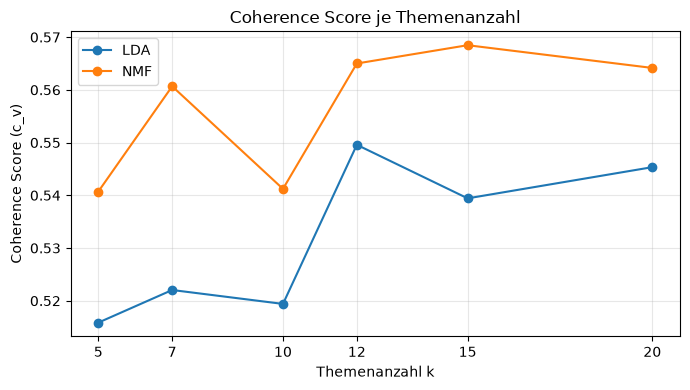

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, gruppe in scores.groupby("verfahren"):
    ax.plot(gruppe["k"], gruppe["coherence"], marker="o", label=name)

ax.set_xlabel("Themenanzahl k")
ax.set_ylabel("Coherence Score (c_v)")
ax.set_xticks(K_WERTE)
ax.set_title("Coherence Score je Themenanzahl")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "coherence_plot.png", dpi=150)
plt.show()

In [16]:

# Da der höchste Coherence Score nicht automatisch die am besten interpretierbaren Themen liefert, werden hier die Top-10-Wörter der aussichtsreichsten Themenanzahlen (LDA: k = 12, 20; NMF: k = 12, 15) ausgegeben und inhaltlich geprüft.

def zeige_lda_themen(k_wert):
    print(f"\n{'='*60}\nLDA – Top-{TOPN}-Wörter für k = {k_wert}\n{'='*60}")
    model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=k_wert,
        random_state=RANDOM_STATE,
        passes=LDA_PASSES,
    )
    for topic_id in range(k_wert):
        woerter = [wort for wort, _ in model.show_topic(topic_id, topn=TOPN)]
        print(f"Thema {topic_id + 1:2d}: {', '.join(woerter)}")

def zeige_nmf_themen(k_wert):
    print(f"\n{'='*60}\nNMF – Top-{TOPN}-Wörter für k = {k_wert}\n{'='*60}")
    model = NMF(n_components=k_wert, random_state=RANDOM_STATE, max_iter=NMF_MAX_ITER)
    model.fit(X_tfidf)
    for topic_id, komponente in enumerate(model.components_):
        top_idx = komponente.argsort()[-TOPN:][::-1]
        woerter = [feature_names[i] for i in top_idx]
        print(f"Thema {topic_id + 1:2d}: {', '.join(woerter)}")

# Kandidaten ausgeben
for k_lda in [12, 20]:
    zeige_lda_themen(k_lda)

for k_nmf in [12, 15]:
    zeige_nmf_themen(k_nmf)


LDA – Top-10-Wörter für k = 12
Thema  1: payment, pay, receive, month, late, account, fee, statement, charge, day
Thema  2: tell, ask, phone, number, time, speak, contact, information, try, company
Thema  3: car, purchase, vehicle, company, pay, charge, contract, insurance, lease, service
Thema  4: report, credit, account, dispute, remove, information, file, reporting, delete, bureau
Thema  5: information, consumer, provide, law, request, file, verify, violation, require, section
Thema  6: debt, collection, letter, owe, company, send, receive, agency, collect, request
Thema  7: credit, report, inquiry, card, score, remove, company, authorize, fraud, hard
Thema  8: receive, request, letter, send, document, state, provide, email, submit, date
Thema  9: file, court, year, bankruptcy, attorney, case, pay, law, try, live
Thema 10: loan, payment, pay, interest, year, month, rate, time, student, apply
Thema 11: account, card, bank, check, charge, money, fee, close, fund, deposit
Thema 12: mo

# Festlegung und Begründung der Themenanzahl

Auf Basis der Coherence Scores  und der inhaltlichen Prüfung der Top-10-Wörter werden für die beiden Verfahren unterschiedliche Themenanzahlen festgelegt:

LDA  = 12
NMF = 15

**Begründung:**
Ziel des Vergleichs ist es, jedes Verfahren unter seinen jeweils besten Bedingungen zu bewerten und nicht künstlich auf eine identische Themenanzahl zu begrenzen. 


**Bekannte Einschränkung:**
In beiden Modellen bleibt ein Thema bestehen, das überwiegend von allgemeinen Wörter geprägt ist. Da das Vokabular aus Notebook 02 unverändert übernommen wurde, um Vergleichbarkeit und Reproduzierbarkeit über alle Schritte hinweg sicherzustellen, wird dieser Effekt bewusst als Einschränkung dokumentiert und bei der weiteren Interpretation berücksichtigt.

